# Tema 4, Exercițiul 3
## Restaurarea unei imagini binare cu un MRF

Vrem să reconstruim o imagine binară mică (pixeli 0 = negru, 1 = alb) afectată de zgomot. Folosim o **rețea Markov** pe o grilă $5 \times 5$, în care fiecare pixel este conectat doar cu vecinii direcți (sus, jos, stânga, dreapta).

Ideea: pixelii vecini tind să aibă aceeași valoare (imaginile reale sunt „netede” local), deci putem folosi această structură pentru a corecta zgomotul.

## Energie și probabilitate

Fie $y$ imaginea observată și $x$ imaginea adevărată necunoscută, cu pixeli binari $x_i$. Un MRF se scrie echivalent printr-o energie $E(x; y)$:

$$P(x \mid y) \propto e^{-E(x; y)}, \qquad E(x; y) = \lambda \sum_i (x_i - y_i)^2 + \sum_{(i,j) \in E} (x_i - x_j)^2, \quad \lambda > 0.$$

Energia nu este o probabilitate. A maximiza $P(x\mid y)$ este echivalent cu a minimiza $E(x;y)$. Cei doi termeni:

- Fidelitate $\lambda \sum_i (x_i - y_i)^2$: penalizează abaterile de la $y$. $\lambda$ = câtă încredere avem în observație.
- Netezime $\sum_{(i,j)} (x_i - x_j)^2$: penalizează vecinii care diferă (preferă zone compacte).

Potențialele corespunzătoare: $\phi_i(x_i) = e^{-\lambda (x_i - y_i)^2}$ și $\phi_{ij}(x_i, x_j) = e^{-(x_i - x_j)^2}$. Produsul lor dă $e^{-E(x;y)}$.

## a) Imaginea binară originală

Construim un pătrat alb $3 \times 3$ pe fond negru, într-o grilă $5 \times 5$.

matricea originala:
[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]


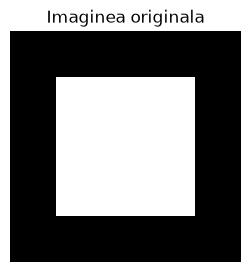

In [1]:
import numpy as np
import matplotlib.pyplot as plt

inaltime = latime = 5
imagine_originala = np.zeros((inaltime, latime), dtype=int)
imagine_originala[1:4, 1:4] = 1          # patrat alb 3x3 in centru

print("matricea originala:")
print(imagine_originala)

plt.figure(figsize=(3, 3))
plt.imshow(imagine_originala, cmap="gray", vmin=0, vmax=1)
plt.title("Imaginea originala")
plt.axis("off")
plt.show()

## b) Imaginea zgomotoasă

Inversăm aleatoriu aproximativ 15% dintre pixeli ($0 \leftrightarrow 1$). Folosim o sămânță fixă pentru reproductibilitate. Notăm imaginea observată cu $y$.

pixeli inversati de zgomot: 5


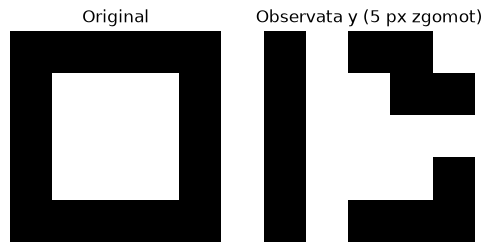

In [ ]:
generator = np.random.default_rng(25)                     # seed fix
masca_zgomot = generator.random((inaltime, latime)) < 0.15  # ~15% dintre pixeli
imagine_observata = imagine_originala.copy()
imagine_observata[masca_zgomot] ^= 1                        # inverseaza 0<->1 pe pixelii alesi

numar_pixeli_zgomot = int(masca_zgomot.sum())
print(f"pixeli inversati de zgomot: {numar_pixeli_zgomot}")

fig, axe = plt.subplots(1, 2, figsize=(6, 3))
axe[0].imshow(imagine_originala, cmap="gray", vmin=0, vmax=1)
axe[0].set_title("Original"); axe[0].axis("off")
axe[1].imshow(imagine_observata, cmap="gray", vmin=0, vmax=1)
axe[1].set_title(f"Observata y ({numar_pixeli_zgomot} px zgomot)"); axe[1].axis("off")
plt.show()

## c) Graful MRF și energia

Fiecare pixel $(i, j)$ este un nod; muchiile leagă pixelii adiacenți (sus/jos/stânga/dreapta). Mai jos funcția `neighbors` enumeră vecinii, iar `energy` evaluează $E(x; y)$.

 Energia o folosim doar pentru verificare, restaurarea minimizează această energie.

In [3]:
def vecini(i, j):
    """Vecinii directi (sus, jos, stanga, dreapta) ai pixelului (i, j)."""
    for di, dj in ((-1, 0), (1, 0), (0, -1), (0, 1)):
        vi, vj = i + di, j + dj
        if 0 <= vi < inaltime and 0 <= vj < latime:
            yield vi, vj

def energie(imagine, observata, lam):
    # termenul de fidelitate: abaterea fata de imaginea observata
    fidelitate = lam * np.sum((imagine - observata) ** 2)
    # termenul de netezime: diferentele intre pixeli vecini
    netezime = 0
    for i in range(inaltime):
        for j in range(latime):
            for vi, vj in vecini(i, j):
                if (vi, vj) > (i, j):          # numaram fiecare muchie o singura data
                    netezime += (imagine[i, j] - imagine[vi, vj]) ** 2
    return fidelitate + netezime

# pe imaginea observata, termenul de fidelitate e 0, deci ramane doar netezimea
print("E(y; y) cu lambda=1:", energie(imagine_observata, imagine_observata, 1))

E(y; y) cu lambda=1: 17


## d) Configurația MAP prin ICM

Pentru $5 \times 5 = 25$ pixeli, spațiul are $2^{25} \approx 3.4 \cdot 10^7$ configurații, deci inferența exactă e costisitoare. Folosim o metodă aproximativă: **ICM** (*Iterated Conditional Modes*):

1. Inițializăm $x = y$.
2. Pentru fiecare pixel (cu vecinii fixați), alegem valoarea $0$ sau $1$ care **minimizează energia locală**:
$$E_{\text{local}}(x_i) = \lambda (x_i - y_i)^2 + \sum_{j \in \text{vecini}(i)} (x_i - x_j)^2.$$
3. Repetăm parcurgerile până la convergență.

ICM coboară monoton energia, dar se oprește într-un **minim local**, nu neapărat în MAP-ul global.

In [4]:
def icm(observata, lam, parcurgeri_max=20):
    imagine = observata.copy()                      # pornim de la imaginea observata
    for _ in range(parcurgeri_max):
        s_a_schimbat = False
        for i in range(inaltime):
            for j in range(latime):
                # alegem valoarea (0 sau 1) cu energia locala minima, cu vecinii fixati
                valoare_optima, energie_optima = imagine[i, j], None
                for valoare in (0, 1):
                    e = lam * (valoare - observata[i, j]) ** 2
                    for vi, vj in vecini(i, j):
                        e += (valoare - imagine[vi, vj]) ** 2
                    if energie_optima is None or e < energie_optima:
                        energie_optima, valoare_optima = e, valoare
                if valoare_optima != imagine[i, j]:
                    imagine[i, j] = valoare_optima
                    s_a_schimbat = True
        if not s_a_schimbat:                        # convergenta: nimic nu s-a mai schimbat
            break
    return imagine

imagine_restaurata = icm(imagine_observata, lam=1.0)
print("restaurata (lambda=1):")
print(imagine_restaurata)
print("erori fata de original:", int(np.sum(imagine_restaurata != imagine_originala)))

restaurata (lambda=1):
[[0 0 0 0 0]
 [0 1 1 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]
erori fata de original: 1


## e) Trei valori ale lui $\lambda$

Rulăm ICM pentru $\lambda \in \{0.3, 1, 3\}$ și comparăm numărul de pixeli reconstruiți greșit față de original.

erori imagine observata (fara restaurare): 5
lambda = 0.3:  erori fata de original = 1,  E = 13.20
lambda = 1.0:  erori fata de original = 1,  E = 16.00
lambda = 3.0:  erori fata de original = 5,  E = 17.00


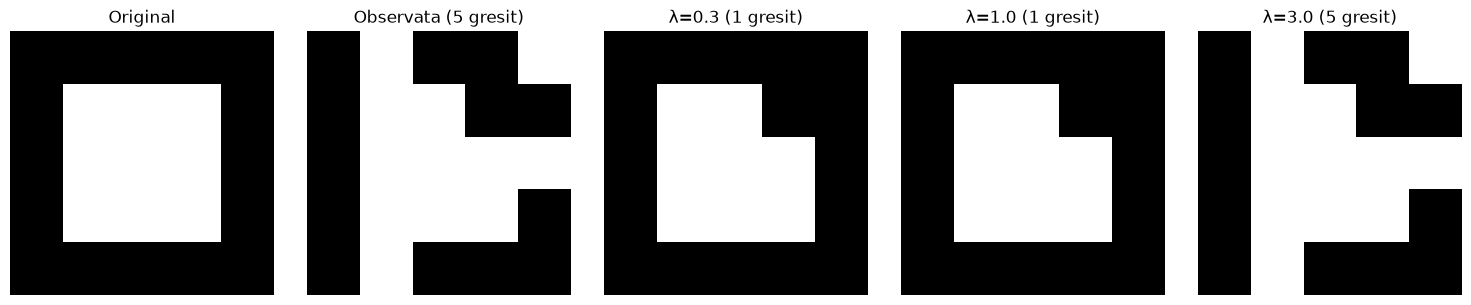

In [5]:
valori_lambda = [0.3, 1.0, 3.0]
# restauram imaginea pentru fiecare lambda
rezultate = {lam: icm(imagine_observata, lam) for lam in valori_lambda}

erori_observata = int(np.sum(imagine_observata != imagine_originala))
print(f"erori imagine observata (fara restaurare): {erori_observata}")
for lam in valori_lambda:
    erori = int(np.sum(rezultate[lam] != imagine_originala))
    print(f"lambda = {lam:>3}:  erori fata de original = {erori},  "
          f"E = {energie(rezultate[lam], imagine_observata, lam):.2f}")

# afisam: original, observata si cele 3 restaurari
fig, axe = plt.subplots(1, len(valori_lambda) + 2, figsize=(3 * (len(valori_lambda) + 2), 3))
axe[0].imshow(imagine_originala, cmap="gray", vmin=0, vmax=1)
axe[0].set_title("Original"); axe[0].axis("off")
axe[1].imshow(imagine_observata, cmap="gray", vmin=0, vmax=1)
axe[1].set_title(f"Observata ({erori_observata} gresit)"); axe[1].axis("off")
for k, lam in enumerate(valori_lambda):
    erori = int(np.sum(rezultate[lam] != imagine_originala))
    axe[k + 2].imshow(rezultate[lam], cmap="gray", vmin=0, vmax=1)
    axe[k + 2].set_title(f"λ={lam} ({erori} gresit)")
    axe[k + 2].axis("off")
plt.tight_layout()
plt.show()

## Interpretare

Imaginea observată avea **5 pixeli greșiți**. După restaurare:

- **$\lambda = 0.3$ și $\lambda = 1$**: domină netezimea → ICM elimină pixelii izolați de zgomot și reface pătratul → **1 pixel greșit**.
- **$\lambda = 3$**: domină fidelitatea → ICM are încredere în $y$ și păstrează zgomotul → tot **5 pixeli greșiți**.

**Rolul lui $\lambda$:** mic favorizează netezirea (curăță zgomotul, dar prea mic șterge detalii); mare favorizează fidelitatea (păstrează detaliile, dar și zgomotul). Optimul e un compromis. ICM găsește un **minim local**, deci o aproximare a MAP-ului, nu neapărat MAP-ul global.